# Employee Churn: Final Model (XGBoost + 5-Seed Averaging)

**Question:** which employees are likely to leave, so HR can talk to them in time?

This notebook contains **only the final, official best model** from `xgboost_best.ipynb`
(the improvement-loop champion, "v0"). Everything that was tested but **not kept** has been removed.

| Kept (used here) | Removed (tested, did not pass) |
|---|---|
| Data cleaning rules + dropping `employee_id` | Early stopping + repeated inner CV (Rung 1) |
| Old recipe: Optuna, 300 trials, 3-fold inner CV, PR-AUC objective | KNN / Iterative filling, target encoding (Rung 2) |
| `scale_pos_weight` for the imbalance | Monotone constraints, leaf-wise trees, bins (Rung 3) |
| **5-seed averaging** | ROS and SMOTE (Rung 4) |
| F1-best cut-off chosen on training data only | Isotonic calibration (Rung 5) |
| SHAP explanations, cost-based cut-offs | dart, stacking, XGB + LR blend (unproven), log-loss tuning |

**Expected results** (same 5 folds as every notebook in the project):
F1 **0.363 ± 0.019**, ROC-AUC **0.741 ± 0.012**, PR-AUC **0.327 ± 0.020**; final cut-off **0.6129**.

**Honesty rule:** every choice (settings, switches, cut-off) is made from training data only.
The 5 test folds are used only to report scores.

**Needs:** `employee_churn_ecommerce_retail_5000_10cols.csv` in the same folder. Runtime ≈ 5 minutes on 15 cores.

## Step 1: Setup

A fixed random seed and fixed trial counts make every run give the **same numbers**.

In [1]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")
import optuna
import joblib
from joblib import Parallel, delayed
from scipy.stats import spearmanr

from sklearn.base import BaseEstimator, TransformerMixin, ClassifierMixin
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, roc_curve,
                             precision_recall_curve, confusion_matrix)
import xgboost as xgb
from xgboost import XGBClassifier

optuna.logging.set_verbosity(optuna.logging.WARNING)

RANDOM_STATE = 42                     # same seed as every notebook in the project
QUICK = os.environ.get("XGB_QUICK") == "1"     # quick test run only; numbers will NOT match
N_TRIALS = 20 if QUICK else 300       # Optuna tries per search (300 = the winning recipe)
N_SEEDS = 5                           # copies averaged in the final model
N_JOBS_FOLDS = 5                      # outer folds tuned side by side
DATA = os.environ.get("CHURN_DATA", "dataset/employee_churn_ecommerce_retail_5000_10cols.csv")
OUT = "charts_xgb_final"
os.makedirs(OUT, exist_ok=True)

BLUE, PURPLE, YELLOW, GREY = "#1D4ED8", "#7E22CE", "#FACC15", "#6B7280"
sns.set_theme(style="whitegrid")
NOTEBOOK_START = time.time()

def save(name):
    plt.tight_layout()
    plt.savefig(f"{OUT}/{name}.png", dpi=150)
    plt.show()

print(f"Tools loaded ✓ | xgboost {xgb.__version__} | trials {N_TRIALS} | seeds {N_SEEDS} | quick mode: {QUICK}")

Tools loaded ✓ | xgboost 3.4.1 | trials 300 | seeds 5 | quick mode: False


## Step 2: Load and clean the data

- `churn` = 1 if `termination_date` is filled in (the person left).
- 10 fixed rules blank out impossible values. Each rule looks at **one row only**, so it is safe before splitting.
- `employee_id` is dropped: its year is **not** a hire year (1,220 people have more tenure than it allows),
  and it might have been recorded after people left, which would leak the answer.

In [2]:
raw = pd.read_csv(DATA)
raw["churn"] = raw["termination_date"].notna().astype(int)
df = raw.drop(columns=["employee_id", "termination_date"]).copy()
EDITS = []

def blank_if(rule, col, mask):
    mask = mask.fillna(False)
    df.loc[mask, col] = np.nan
    EDITS.append((rule, int(mask.sum())))

blank_if("tenure > age − 16", "years_at_company", df["years_at_company"] > df["age"] - 16)
blank_if("age outside 16–80", "age", (df["age"] < 16) | (df["age"] > 80))
blank_if("job_satisfaction outside 1–100", "job_satisfaction",
         (df["job_satisfaction"] < 1) | (df["job_satisfaction"] > 100))
blank_if("performance_rating outside 1–5", "performance_rating",
         (df["performance_rating"] < 1) | (df["performance_rating"] > 5))
blank_if("monthly_salary ≤ 0", "monthly_salary", df["monthly_salary"] <= 0)
blank_if("overtime < 0 or > 200 h", "overtime_hours_per_month",
         (df["overtime_hours_per_month"] < 0) | (df["overtime_hours_per_month"] > 200))
blank_if("years_at_company < 0", "years_at_company", df["years_at_company"] < 0)
for c in ["department", "job_level"]:
    tidy = df[c].str.strip().str.title().where(df[c].notna())
    EDITS.append((f"tidy spelling of {c}", int((tidy.fillna("§") != df[c].fillna("§")).sum())))
    df[c] = tidy
dups = df.duplicated()
df = df[~dups].reset_index(drop=True)
EDITS.append(("duplicate rows removed", int(dups.sum())))

print(pd.DataFrame(EDITS, columns=["Cleaning rule", "Cells / rows changed"]).to_string(index=False))

X = df.drop(columns=["churn"])
y = df["churn"]
number_cols = X.select_dtypes("number").columns.tolist()
text_cols = X.select_dtypes(exclude="number").columns.tolist()
if not QUICK:
    assert len(X) == 5000 and y.sum() == 613, "rows or leavers changed!"
print(f"\nRows: {len(X):,} | leavers: {y.sum()} ({y.mean():.1%}) | clue columns: {X.shape[1]}")

                 Cleaning rule  Cells / rows changed
             tenure > age − 16                     0
             age outside 16–80                     0
job_satisfaction outside 1–100                     0
performance_rating outside 1–5                     0
            monthly_salary ≤ 0                     0
       overtime < 0 or > 200 h                     0
          years_at_company < 0                     0
   tidy spelling of department                     0
    tidy spelling of job_level                     0
        duplicate rows removed                     0

Rows: 5,000 | leavers: 613 (12.3%) | clue columns: 8


## Step 3: Folds and scoring tools

- **5 outer folds** (stratified, seed 42): the same test folds as every notebook, used only for reporting.
- **Inner 3-fold CV** (seed 42): Optuna tunes on it, inside each training part.
- **Cut-off CV** (5 folds, seed 1042): predictions on the training part, used to pick the F1-best cut-off.
- The cut-off is **not 0.5**: with only 12% leavers the model rarely gives anyone more than 50%.

In [3]:
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
outer_splits = list(folds.split(X, y))
inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
CUTOFF_CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE + 1000)

METRICS = ["accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc"]
METRIC_LABELS = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC", "PR-AUC"]

def cv_metrics(p, thr):
    # Score out-of-fold chances p on each outer fold, each fold at its own cut-off.
    out = {m: [] for m in METRICS}
    for (_, te), t in zip(outer_splits, thr):
        yt, pt = y.iloc[te], p[te]
        pred = (pt >= t).astype(int)
        out["accuracy"].append(accuracy_score(yt, pred))
        out["precision"].append(precision_score(yt, pred, zero_division=0))
        out["recall"].append(recall_score(yt, pred))
        out["f1"].append(f1_score(yt, pred))
        out["roc_auc"].append(roc_auc_score(yt, pt))
        out["pr_auc"].append(average_precision_score(yt, pt))
    return {m: np.array(v) for m, v in out.items()}

def best_threshold(y_true, p):
    # The cut-off with the highest F1 on these (training-only) predictions.
    prec, rec, thr = precision_recall_curve(y_true, p)
    f1 = 2 * prec * rec / np.clip(prec + rec, 1e-12, None)
    return float(thr[np.argmax(f1[:-1])])

def inner_oof(model, X_tr, y_tr, cv):
    # Chances for a training part from inner folds (never touches the outer test part).
    return cross_val_predict(model, X_tr, y_tr, cv=cv, method="predict_proba")[:, 1]

def fmt(a):
    return f"{np.mean(a):.3f} ± {np.std(a):.3f}"

print("Test fold sizes:", [len(te) for _, te in outer_splits],
      "| leavers per fold:", [int(y.iloc[te].sum()) for _, te in outer_splits])

Test fold sizes: [1000, 1000, 1000, 1000, 1000] | leavers per fold: [122, 122, 123, 123, 123]


## Step 4: The model recipe

**Pipeline** (everything learned is learned in `fit()`, so it only ever sees training data):

1. **Clue columns** (Optuna switches each on or off): overtime × dissatisfaction, salary vs level median,
   salary vs department median, tenure ÷ age, tenure bucket, satisfaction × performance.
2. **Cleaning:** blank numbers → median (optionally with "was blank" flags);
   departments and levels → XGBoost's native categories or one-hot columns.
3. **XGBoost**, with `scale_pos_weight` to give leavers more weight.
4. **5-seed averaging:** 5 copies with seeds 42–46, chances averaged. This was the only XGBoost upgrade that passed.

**Search:** Optuna (TPE sampler + median pruning) tries settings and keeps the best **mean PR-AUC over 3 inner folds**.

In [4]:
CLUES = ["ot_x_dissat", "salary_vs_level", "salary_vs_dept", "tenure_ratio", "tenure_bucket", "sat_x_perf"]

class ChurnFeatures(BaseEstimator, TransformerMixin):
    # Adds the switched-on clue columns. Medians and category lists are learned in fit().

    def __init__(self, ot_x_dissat=False, salary_vs_level=False, salary_vs_dept=False,
                 tenure_ratio=False, tenure_bucket=False, sat_x_perf=False, native_cat=False):
        self.ot_x_dissat = ot_x_dissat
        self.salary_vs_level = salary_vs_level
        self.salary_vs_dept = salary_vs_dept
        self.tenure_ratio = tenure_ratio
        self.tenure_bucket = tenure_bucket
        self.sat_x_perf = sat_x_perf
        self.native_cat = native_cat

    def fit(self, X, y=None):
        self.level_median_ = X.groupby("job_level")["monthly_salary"].median()
        self.dept_median_ = X.groupby("department")["monthly_salary"].median()
        self.salary_median_ = X["monthly_salary"].median()
        self.categories_ = {c: sorted(X[c].dropna().unique()) for c in text_cols}
        return self

    def transform(self, X):
        X = X.copy()
        sal = X["monthly_salary"]
        if self.ot_x_dissat:
            X["ot_x_dissat"] = X["overtime_hours_per_month"] * (100 - X["job_satisfaction"])
        if self.salary_vs_level:
            X["salary_vs_level"] = sal / X["job_level"].map(self.level_median_).astype(float).fillna(self.salary_median_)
        if self.salary_vs_dept:
            X["salary_vs_dept"] = sal / X["department"].map(self.dept_median_).astype(float).fillna(self.salary_median_)
        if self.tenure_ratio:
            X["tenure_ratio"] = X["years_at_company"] / X["age"]
        if self.tenure_bucket:
            X["tenure_bucket"] = pd.cut(X["years_at_company"], [-np.inf, 1, 2, 4, 7, np.inf], labels=False)
        if self.sat_x_perf:
            X["sat_x_perf"] = X["job_satisfaction"] * X["performance_rating"]
        if self.native_cat:
            for c in text_cols:
                X[c] = pd.Categorical(X[c], categories=self.categories_[c])
        return X


def make_xgb_pipe(impute=True, add_indicator=False, native_cat=False, seed=RANDOM_STATE, **params):
    # clues → cleaning → XGBoost
    clues = {f: params.pop(f, False) for f in CLUES}
    numbers = SimpleImputer(strategy="median", add_indicator=add_indicator) if impute else "passthrough"
    text = "passthrough" if native_cat else Pipeline([
        ("fill_blanks", SimpleImputer(strategy="most_frequent")),
        ("to_numbers", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    cleaning = ColumnTransformer([
        ("numbers", numbers, make_column_selector(dtype_include="number")),
        ("text", text, make_column_selector(dtype_exclude="number")),
    ], verbose_feature_names_out=False).set_output(transform="pandas")
    model = XGBClassifier(**params, enable_categorical=True, tree_method="hist",
                          eval_metric="logloss", random_state=seed, n_jobs=1)
    return Pipeline([("features", ChurnFeatures(**clues, native_cat=native_cat)),
                     ("prep", cleaning), ("model", model)])


class SeedAvgXGB(ClassifierMixin, BaseEstimator):
    # Average of n_seeds copies of the same recipe (seeds 42, 43, ...).

    def __init__(self, params=None, n_seeds=N_SEEDS):
        self.params = params
        self.n_seeds = n_seeds

    def fit(self, X, y):
        self.classes_ = np.unique(y)
        self.models_ = [make_xgb_pipe(**dict(self.params), seed=RANDOM_STATE + i).fit(X, y)
                        for i in range(self.n_seeds)]
        return self

    def predict_proba(self, X):
        return np.mean([m.predict_proba(X) for m in self.models_], axis=0)

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)


def suggest_params(trial, fixed=None):
    # The search space: XGBoost settings + on/off switches (a switch in `fixed` is not searched).
    fixed = fixed or {}
    switch = lambda name: fixed[name] if name in fixed else trial.suggest_categorical(name, [True, False])
    p = dict(
        n_estimators=trial.suggest_int("n_estimators", 100, 800, step=50),
        learning_rate=trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
        max_depth=trial.suggest_int("max_depth", 2, 8),
        min_child_weight=trial.suggest_int("min_child_weight", 1, 20),
        subsample=trial.suggest_float("subsample", 0.5, 1.0),
        colsample_bytree=trial.suggest_float("colsample_bytree", 0.5, 1.0),
        gamma=trial.suggest_float("gamma", 0.0, 5.0),
        reg_alpha=trial.suggest_float("reg_alpha", 1e-3, 10, log=True),
        reg_lambda=trial.suggest_float("reg_lambda", 1e-3, 10, log=True),
        scale_pos_weight=trial.suggest_float("scale_pos_weight", 1.0, 7.2),
        max_delta_step=trial.suggest_int("max_delta_step", 0, 10),
        impute=switch("impute"),
        native_cat=switch("native_cat"),
    )
    if p["impute"]:
        p["add_indicator"] = switch("add_indicator")
    for f in CLUES:
        p[f] = switch(f)
    return p


def tune_xgb(X_tr, y_tr, fixed=None):
    # Optuna on the training part only: mean PR-AUC over 3 inner folds, with pruning.
    optuna.logging.set_verbosity(optuna.logging.WARNING)
    def objective(trial):
        params = suggest_params(trial, fixed)
        aps = []
        for step, (a, b) in enumerate(inner_cv.split(X_tr, y_tr)):
            m = make_xgb_pipe(**params).fit(X_tr.iloc[a], y_tr.iloc[a])
            aps.append(average_precision_score(y_tr.iloc[b], m.predict_proba(X_tr.iloc[b])[:, 1]))
            trial.report(np.mean(aps), step)
            if trial.should_prune():
                raise optuna.TrialPruned()
        return float(np.mean(aps))
    study = optuna.create_study(direction="maximize",
                                sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE),
                                pruner=optuna.pruners.MedianPruner(n_startup_trials=10, n_warmup_steps=0))
    study.optimize(objective, n_trials=N_TRIALS)
    return study

print("Model recipe ready ✓")

Model recipe ready ✓


## Step 5: Honest score with nested 5-fold cross-validation

For each of the 5 outer folds:
1. Lock away the 1,000 test employees.
2. On the other 4,000, Optuna tries 300 settings (scored on 3 inner folds).
3. Build the 5-seed model with the best settings and pick its F1-best cut-off from training-only predictions.
4. Train on all 4,000 and predict the locked 1,000 **once**.

In [5]:
def run_fold(i):
    optuna.logging.set_verbosity(optuna.logging.WARNING)
    tr, te = outer_splits[i]
    X_tr, y_tr = X.iloc[tr], y.iloc[tr]
    study = tune_xgb(X_tr, y_tr)
    model = SeedAvgXGB(study.best_params)
    train_oof = inner_oof(model, X_tr, y_tr, CUTOFF_CV)
    test = model.fit(X_tr, y_tr).predict_proba(X.iloc[te])[:, 1]
    return dict(params=study.best_params, thr=best_threshold(y_tr, train_oof),
                train_oof=train_oof, test=test)

t0 = time.time()
runs = Parallel(n_jobs=N_JOBS_FOLDS)(delayed(run_fold)(i) for i in range(5))
fold_params = [r["params"] for r in runs]
fold_thr = [r["thr"] for r in runs]
oof = np.zeros(len(y))
for (_, te), r in zip(outer_splits, runs):
    oof[te] = r["test"]
scores = cv_metrics(oof, fold_thr)

print(f"Nested CV: {(time.time() - t0) / 60:.1f} min")
print("Cut-off per fold:", [round(t, 3) for t in fold_thr], f"(mean {np.mean(fold_thr):.3f})")
print("F1 per fold:     ", [round(float(v), 4) for v in scores["f1"]])
print()
for m, lab in zip(METRICS, METRIC_LABELS):
    print(f"  {lab:10} {fmt(scores[m])}")

EXPECTED = {"f1": 0.363, "roc_auc": 0.741, "pr_auc": 0.327}
if not QUICK:
    got = {m: round(scores[m].mean(), 3) for m in EXPECTED}
    print("\n✓ Matches the champion (v0)" if got == EXPECTED
          else f"\n⚠ Differs from the champion {EXPECTED}: got {got}")

Nested CV: 3.4 min
Cut-off per fold: [0.177, 0.355, 0.164, 0.202, 0.221] (mean 0.224)
F1 per fold:      [0.3736, 0.3653, 0.3708, 0.3256, 0.3785]

  Accuracy   0.787 ± 0.012
  Precision  0.287 ± 0.012
  Recall     0.496 ± 0.055
  F1         0.363 ± 0.019
  ROC-AUC    0.741 ± 0.012
  PR-AUC     0.327 ± 0.020

✓ Matches the champion (v0)


## Step 6: Confusion matrix (counting people)

Every employee is predicted once, by the model of the fold where they were in the test part,
at that fold's own cut-off.

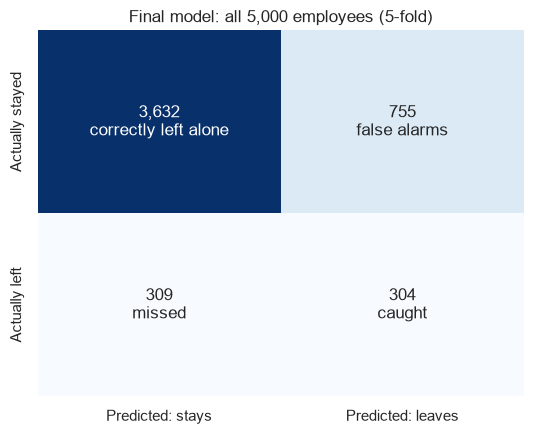

Caught 304 of 613 leavers (49.6%) | missed 309 | false alarms 755
Precision 28.7% | false alarms per leaver caught 2.48


In [6]:
pred = np.zeros(len(y), dtype=int)
for (_, te), t in zip(outer_splits, fold_thr):
    pred[te] = (oof[te] >= t).astype(int)
tn, fp, fn, tp = confusion_matrix(y, pred).ravel()

fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap([[tn, fp], [fn, tp]], annot=[[f"{tn:,}\ncorrectly left alone", f"{fp:,}\nfalse alarms"],
                                         [f"{fn:,}\nmissed", f"{tp:,}\ncaught"]],
            fmt="", cmap="Blues", cbar=False, ax=ax,
            xticklabels=["Predicted: stays", "Predicted: leaves"],
            yticklabels=["Actually stayed", "Actually left"])
ax.set_title(f"Final model: all {len(y):,} employees (5-fold)")
save("01_confusion_matrix")

print(f"Caught {tp} of {tp + fn} leavers ({tp / (tp + fn):.1%}) | missed {fn} | false alarms {fp}")
print(f"Precision {tp / (tp + fp):.1%} | false alarms per leaver caught {fp / tp:.2f}")

## Step 7: ROC and precision-recall curves

Drawn **per fold** (each fold's model has its own probability scale), then averaged with a ± 1 std band.

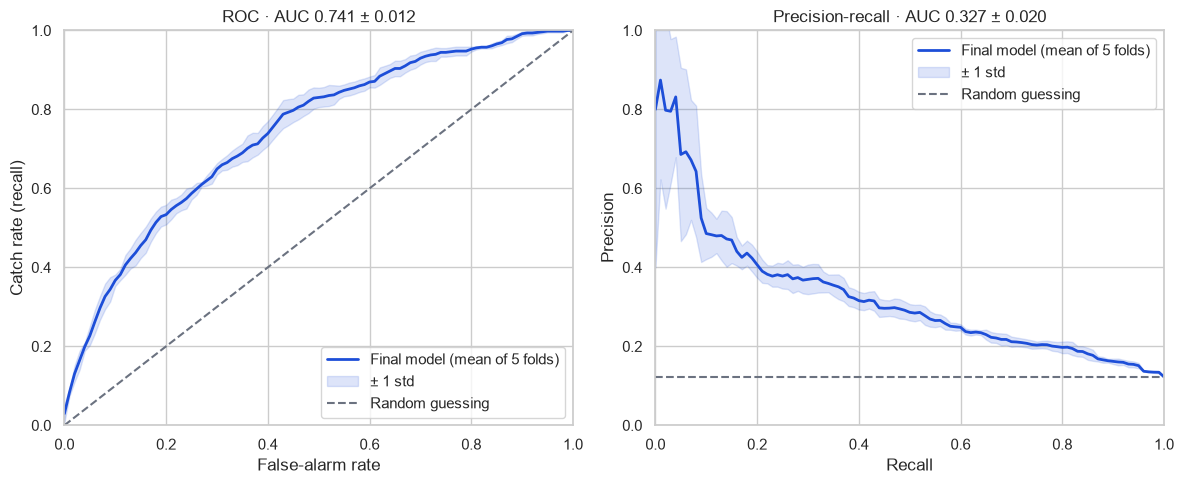

At 20% false alarms the model catches 53.3% of leavers
At 50% recall, precision is 28.6%


In [7]:
GRID = np.linspace(0, 1, 101)
rocs, prs = [], []
for _, te in outer_splits:
    yt, pt = y.iloc[te], oof[te]
    fpr, tpr, _ = roc_curve(yt, pt)
    rocs.append(np.interp(GRID, fpr, tpr))
    prec, rec, _ = precision_recall_curve(yt, pt)
    prs.append(np.interp(GRID, rec[::-1], prec[::-1]))
rocs, prs = np.array(rocs), np.array(prs)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, curves, xl, yl, title, base in [
        (axes[0], rocs, "False-alarm rate", "Catch rate (recall)", f"ROC · AUC {fmt(scores['roc_auc'])}", GRID),
        (axes[1], prs, "Recall", "Precision", f"Precision-recall · AUC {fmt(scores['pr_auc'])}",
         np.full_like(GRID, y.mean()))]:
    m, s = curves.mean(0), curves.std(0)
    ax.plot(GRID, m, color=BLUE, lw=2, label="Final model (mean of 5 folds)")
    ax.fill_between(GRID, m - s, m + s, color=BLUE, alpha=0.15, label="± 1 std")
    ax.plot(GRID, base, "--", color=GREY, label="Random guessing")
    ax.set(xlabel=xl, ylabel=yl, title=title, xlim=(0, 1), ylim=(0, 1))
    ax.legend(loc="lower right" if ax is axes[0] else "upper right")
save("02_roc_pr")

print(f"At 20% false alarms the model catches {rocs[:, 20].mean():.1%} of leavers")
print(f"At 50% recall, precision is {prs[:, 50].mean():.1%}")

## Step 8: The final model (trained on all 5,000 employees)

1. **Switches** (clue columns, blank filling, categories): each kept if at least 3 of the 5 folds chose it.
2. **Settings:** one more Optuna search (300 trials) on all the data, with those switches fixed.
3. **5-seed averaging**, then the **F1-best cut-off** from 5-fold predictions on all the data.

The final cut-off (≈ 0.61) is much higher than the fold cut-offs (≈ 0.22) because this search chose a larger
`scale_pos_weight` (≈ 6.8), which pushes every chance up. **Use this cut-off only with this final model.**

In [8]:
SWITCHES = ["impute", "add_indicator", "native_cat"] + CLUES
votes = {s: sum(bool(p.get(s, False)) for p in fold_params) for s in SWITCHES}
final_switches = {s: n >= 3 for s, n in votes.items()}
if not final_switches["impute"]:
    final_switches.pop("add_indicator")

t0 = time.time()
final_study = tune_xgb(X, y, fixed=final_switches)
final_params = {**final_study.best_params, **final_switches}
final_model = SeedAvgXGB(final_params)
final_thr = best_threshold(y, inner_oof(final_model, X, y, CUTOFF_CV))
final_model.fit(X, y)
print(f"Final model: {(time.time() - t0) / 60:.1f} min\n")

print("Switches ON: ", [s for s, v in final_switches.items() if v])
print("Switches OFF:", [s for s, v in final_switches.items() if not v])
print("\nXGBoost settings:")
for k, v in final_study.best_params.items():
    print(f"  {k:18} {round(v, 5) if isinstance(v, float) else v}")
print(f"  {'copies (seeds)':18} {N_SEEDS}")
print(f"\nFINAL CUT-OFF: {final_thr:.4f} → flag as 'will leave' if chance ≥ {final_thr:.1%}")

p_all = final_model.predict_proba(X)[:, 1]
train_auc, train_f1 = roc_auc_score(y, p_all), f1_score(y, (p_all >= final_thr).astype(int))
print("\nOverfitting check          ROC-AUC    F1")
print(f"  seen (training data)     {train_auc:.3f}    {train_f1:.3f}")
print(f"  unseen (nested CV)       {scores['roc_auc'].mean():.3f}    {scores['f1'].mean():.3f}")
print(f"  gap                      {train_auc - scores['roc_auc'].mean():+.3f}   {train_f1 - scores['f1'].mean():+.3f}")
if not QUICK:
    print("\n✓ Final cut-off matches the champion (0.6129)" if round(final_thr, 4) == 0.6129
          else f"\n⚠ Final cut-off differs from the champion's 0.6129: got {final_thr:.4f}")

Final model: 1.8 min

Switches ON:  ['impute', 'add_indicator', 'native_cat', 'ot_x_dissat', 'tenure_bucket', 'sat_x_perf']
Switches OFF: ['salary_vs_level', 'salary_vs_dept', 'tenure_ratio']

XGBoost settings:
  n_estimators       250
  learning_rate      0.01655
  max_depth          2
  min_child_weight   19
  subsample          0.89185
  colsample_bytree   0.56484
  gamma              0.08927
  reg_alpha          0.00224
  reg_lambda         0.17055
  scale_pos_weight   6.80329
  max_delta_step     4
  copies (seeds)     5

FINAL CUT-OFF: 0.6129 → flag as 'will leave' if chance ≥ 61.3%

Overfitting check          ROC-AUC    F1
  seen (training data)     0.772    0.384
  unseen (nested CV)       0.741    0.363
  gap                      +0.031   +0.021

✓ Final cut-off matches the champion (0.6129)


## Step 9: What drives the risk (SHAP)

SHAP measures, for each employee, how much each clue **pushed their risk up or down** (in log-odds),
averaged over the 5 copies. Department and level one-hot columns are added back into one clue each.

                                   mean |SHAP|  share                     direction
job satisfaction                        0.2498  22.1%  higher → LESS risk (ρ -0.97)
monthly salary                          0.2185  19.4%  higher → LESS risk (ρ -0.95)
overtime × dissatisfaction              0.1821  16.1%  higher → MORE risk (ρ +0.96)
satisfaction × performance              0.1517  13.4%  higher → LESS risk (ρ -0.95)
overtime hours per month                0.1253  11.1%  higher → MORE risk (ρ +0.92)
job level                               0.1024   9.1%                      category
years at company                        0.0452   4.0%  higher → LESS risk (ρ -0.93)
department                              0.0380   3.4%                      category
performance rating                      0.0078   0.7%  higher → LESS risk (ρ -0.85)
age                                     0.0041   0.4%  higher → MORE risk (ρ +0.09)
tenure bucket                           0.0030   0.3%  higher → LESS risk (ρ

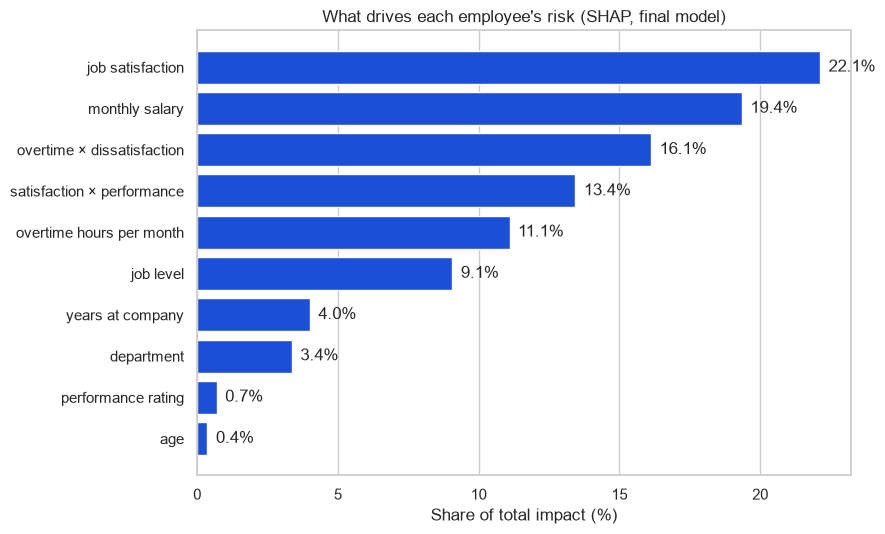

In [9]:
NICE = {"ot_x_dissat": "overtime × dissatisfaction", "salary_vs_level": "salary vs level median",
        "salary_vs_dept": "salary vs dept median", "tenure_ratio": "tenure ÷ age",
        "tenure_bucket": "tenure bucket", "sat_x_perf": "satisfaction × performance"}
def pretty(f):
    if f.startswith("missingindicator_"):
        return "blank: " + pretty(f.removeprefix("missingindicator_"))
    return NICE.get(f, f.replace("_", " "))

vals = []
for m in final_model.models_:
    Xt = m[:-1].transform(X)
    contrib = m.named_steps["model"].get_booster().predict(
        xgb.DMatrix(Xt, enable_categorical=True), pred_contribs=True)
    vals.append(pd.DataFrame(contrib[:, :-1], columns=Xt.columns, index=X.index))
sv = sum(vals) / len(vals)
groups = {c: next((t for t in text_cols if c.startswith(t + "_")), c) for c in sv.columns}
sv = sv.T.groupby(groups).sum().T
importance = sv.abs().mean().sort_values(ascending=False)

def direction(f):
    if f not in Xt.columns or Xt[f].dtype.kind not in "fi":
        return "category"
    v = Xt[f].to_numpy(dtype=float); ok = ~np.isnan(v)
    if np.ptp(sv[f].to_numpy()[ok]) == 0:
        return "never used"
    rho = spearmanr(v[ok], sv[f].to_numpy()[ok]).statistic
    return f"higher → {'MORE' if rho > 0 else 'LESS'} risk (ρ {rho:+.2f})"

shap_table = pd.DataFrame({"mean |SHAP|": importance.round(4),
                           "share": (importance / importance.sum()).map("{:.1%}".format),
                           "direction": [direction(f) for f in importance.index]})
shap_table.index = [pretty(f) for f in shap_table.index]
print(shap_table.to_string())

top = importance.head(10)[::-1]
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh([pretty(f) for f in top.index], top / importance.sum() * 100, color=BLUE)
for i, v in enumerate(top / importance.sum() * 100):
    ax.text(v + 0.3, i, f"{v:.1f}%", va="center")
ax.set(xlabel="Share of total impact (%)", title="What drives each employee's risk (SHAP, final model)")
ax.grid(axis="y", visible=False)
save("03_shap_drivers")

## Step 10: Choosing a cut-off by HR's cost

F1 treats a missed leaver and a false alarm about equally. HR usually doesn't.
**Cost = missed leavers × C + false alarms**, where C = how many times worse a miss is.
Each fold's cut-off is chosen on its **training** predictions to minimise cost, then applied to its test part.

In [10]:
def cost_cutoff(y_true, p, C):
    cands = np.unique(np.r_[p, 1.0 + 1e-9])
    costs = [((p < t) & (y_true == 1)).sum() * C + ((p >= t) & (y_true == 0)).sum() for t in cands]
    return float(cands[int(np.argmin(costs))])

rows = []
for C in [3, 5, 10]:
    missed = fa = 0
    cuts = []
    for (tr, te), r in zip(outer_splits, runs):
        t = cost_cutoff(y.iloc[tr].to_numpy(), r["train_oof"], C)
        cuts.append(t)
        yt, pt = y.iloc[te].to_numpy(), oof[te]
        missed += int(((pt < t) & (yt == 1)).sum())
        fa += int(((pt >= t) & (yt == 0)).sum())
    rows.append({"C (miss costs C× a false alarm)": C, "missed": missed, "false alarms": fa,
                 "total cost": missed * C + fa, "flag nobody": int(y.sum()) * C,
                 "mean cut-off (fold scale)": round(np.mean(cuts), 3)})
cost_df = pd.DataFrame(rows)
print(cost_df.to_string(index=False))
print("\nThe more a lost employee costs, the LOWER the cut-off should be (flag more people).")

 C (miss costs C× a false alarm)  missed  false alarms  total cost  flag nobody  mean cut-off (fold scale)
                               3     410           384        1614         1839                      0.289
                               5     285           863        2288         3065                      0.210
                              10     123          2056        3286         6130                      0.127

The more a lost employee costs, the LOWER the cut-off should be (flag more people).


## Step 11: Summary and saved model

The final model is saved to `final_model.joblib` together with its cut-off.
To load it later, run Steps 1 and 4 first (they define the model classes), then:

```python
bundle = joblib.load("final_model.joblib")
risk = bundle["model"].predict_proba(new_employees)[:, 1]
flag = risk >= bundle["cutoff"]
```

In [11]:
joblib.dump({"model": final_model, "cutoff": final_thr, "params": final_params,
             "columns": list(X.columns)}, "final_model.joblib")

print("=" * 66)
print("FINAL MODEL · XGBoost + 5-seed averaging · nested 5-fold CV")
print("=" * 66)
for m, lab in zip(METRICS, METRIC_LABELS):
    print(f"  {lab:10} {fmt(scores[m])}")
print(f"  {'Fold cut-offs':10} {[round(t, 3) for t in fold_thr]} (mean {np.mean(fold_thr):.3f})")
print(f"\n  Caught {tp} / {tp + fn} leavers | false alarms {fp} | missed {fn}")
print(f"  Final model cut-off: {final_thr:.4f}")
print(f"  Top 3 drivers: {', '.join(pretty(f) for f in importance.index[:3])}")
print(f"\n  Saved: final_model.joblib | charts in {OUT}/: {sorted(os.listdir(OUT))}")
print(f"  Total runtime: {(time.time() - NOTEBOOK_START) / 60:.1f} min")

FINAL MODEL · XGBoost + 5-seed averaging · nested 5-fold CV
  Accuracy   0.787 ± 0.012
  Precision  0.287 ± 0.012
  Recall     0.496 ± 0.055
  F1         0.363 ± 0.019
  ROC-AUC    0.741 ± 0.012
  PR-AUC     0.327 ± 0.020
  Fold cut-offs [0.177, 0.355, 0.164, 0.202, 0.221] (mean 0.224)

  Caught 304 / 613 leavers | false alarms 755 | missed 309
  Final model cut-off: 0.6129
  Top 3 drivers: job satisfaction, monthly salary, overtime × dissatisfaction

  Saved: final_model.joblib | charts in charts_xgb_final/: ['01_confusion_matrix.png', '02_roc_pr.png', '03_shap_drivers.png']
  Total runtime: 5.3 min


### Conclusion

- **This is the official best version.** It is the improvement-loop champion; no challenger passed the strict
  15-fold test (the XGB + LR + RF blend won 9/15 folds, log-loss tuning 7/15; 10 were needed).
- **It catches about half of all leavers** at the F1-best cut-off, raising roughly 2.5 false alarms per leaver caught.
- **Main drivers:** low job satisfaction, low salary, and overtime combined with dissatisfaction.
- **The limit is the data, not the model:** every idea tested landed between F1 0.357 and 0.369.
  Better results need new information (manager changes, promotion history, engagement surveys).
- **For HR:** choose the cut-off from the real cost of losing an employee (Step 10), not only from F1.